# Experiment 13 — Matched-Oracle and Within-Scenario Reliability Audit

**Objective:** correct the two main interpretive limitations of Experiment 12 without tuning any parameters. The simulator is synthetic; no flight-safety claim follows.

1. **Matched-information oracle:** identical allocator, margin, switching penalty, critical priority and temporal logic, but supplied latent true capability (`score=cap`, `sigma=0`). This is a **perfect-information policy reference**, not a globally optimal policy. Its outcome can be worse than the imperfect-information policy on some metrics/worlds.
2. **Perfect-information upper bound:** per-step maximum safe task value, without switching cost; provides a distinct upper bound on safe utility.
3. **Paired worlds:** each policy and oracle are evaluated on the same world.
4. **Within-scenario associations:** correlations are estimated separately for each scenario and descriptive; avoid pooled pseudo-replication.

**Fixed policy parameters:** margin 0.25, switching penalty 1.4, critical bonus 10. No search or parameter selection.

In [1]:
import os, json, zipfile
from itertools import product
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from IPython.display import display
SEED=20261025; T=80; N_UAV=5; N_TASK=5
REQ=np.array([78.,67.,55.,43.,32.]); VALUE=np.array([10.,8.,6.,4.,2.])
MARGIN=.25; PENALTY=1.4; CRITICAL_BONUS=10.
REPS_MAIN=60; REPS_ROBUST=40; N_BOOT=2000
SCENARIOS={'low_noise':(5.,0.),'moderate_noise':(12.,0.),'high_noise':(22.,0.),'moderate_pessimistic_shift':(18.,-13.)}
ROBUST_SCENARIOS={'severe_shift':(22.,-20.),'biased_optimism':(12.,12.),'very_high_noise':(30.,0.)}
OUT='/content/Decision_Reliability_Matched_Oracle_Results' if os.path.isdir('/content') else 'Decision_Reliability_Matched_Oracle_Results'
os.makedirs(OUT,exist_ok=True)
print('Output:',OUT)

Output: Decision_Reliability_Matched_Oracle_Results


In [2]:
def make_world(seed,noise_sd,bias):
    rng=np.random.default_rng(seed)
    cap=np.empty((T,N_UAV)); cap[0]=rng.uniform(68,97,N_UAV)
    onset=rng.integers(12,52,N_UAV); rate=rng.uniform(.35,1.2,N_UAV)
    for t in range(1,T):
        cap[t]=np.clip(cap[t-1]+rng.normal(0,.65,N_UAV)-(t>=onset)*rate,0,100)
    obs=np.clip(cap+rng.normal(0,noise_sd,cap.shape)+bias,0,100)
    sigma=np.full_like(obs,noise_sd if bias==0 else noise_sd*.5)
    return cap,obs,sigma

def allocate(score,sigma,previous,margin,penalty,critical_bonus):
    effective=score-margin*sigma
    eligible=effective[:,None]>=REQ[None,:]
    values=VALUE.copy();values[0]+=critical_bonus
    utility=np.where(eligible,values[None,:]+.001*score[:,None],-1e5)
    if penalty:
        for j in range(N_TASK):
            if previous[j]>=0:
                utility[:,j]-=np.where(np.arange(N_UAV)==previous[j],0,penalty)
    payoff=np.vstack([utility,np.zeros((N_TASK,N_TASK))])
    rows,cols=linear_sum_assignment(-payoff)
    current=np.full(N_TASK,-1,int)
    for i,j in zip(rows,cols):
        if i<N_UAV and eligible[i,j]:current[j]=i
    return current

def simulate(world,margin,penalty,critical_bonus):
    cap,obs,sigma=world;prev=np.full(N_TASK,-1,int)
    unsafe=deferred=switches=critical=0;safe_utility=0.
    for t in range(T):
        curr=allocate(obs[t],sigma[t],prev,margin,penalty,critical_bonus)
        assigned=curr>=0;safe=np.zeros(N_TASK,bool)
        safe[assigned]=cap[t,curr[assigned]]>=REQ[assigned]
        unsafe+=int((assigned&~safe).sum());deferred+=int((~assigned).sum())
        switches+=int(((curr!=prev)&(curr>=0)&(prev>=0)).sum())
        safe_utility+=float(VALUE[safe].sum());critical+=int(safe[0]);prev=curr
    return {'unsafe_per_opportunity':unsafe/(T*N_TASK),
            'deferral_rate':deferred/(T*N_TASK),
            'safe_utility_ratio':safe_utility/(T*VALUE.sum()),
            'critical_safe_rate':critical/T,'switches':switches}
METRICS=['unsafe_per_opportunity','safe_utility_ratio','deferral_rate','critical_safe_rate','switches']
# Assert exact expected behavior and basic metric bounds
w=make_world(SEED,5.,0.)
assert all(0<=simulate(w,0,0,0)[k]<=1 for k in METRICS[:-1])
assert np.allclose(make_world(SEED,5.,0.)[0],w[0])
print('Model smoke test passed')

Model smoke test passed


In [3]:
def oracle_step(cap_t):
    feasible=cap_t[:,None]>=REQ[None,:]
    payoff=np.vstack([np.where(feasible,VALUE[None,:],-1e5),np.zeros((N_TASK,N_TASK))])
    r,c=linear_sum_assignment(-payoff)
    chosen=np.full(N_TASK,-1,dtype=int)
    for i,j in zip(r,c):
        if i<N_UAV and feasible[i,j]:chosen[j]=i
    return chosen

def audit_world(world,margin,penalty,critical_bonus):
    cap,obs,sigma=world
    previous=np.full(N_TASK,-1,dtype=int)
    true_pos=false_neg=true_neg=false_pos=0
    assigned_unsafe=assigned_count=deferred=missed_feasible=0
    oracle_safe=policy_safe=critical=sw=0
    for t in range(T):
        truth=cap[t,:,None]>=REQ[None,:]
        predicted=(obs[t,:,None]-margin*sigma[t,:,None])>=REQ[None,:]
        true_pos+=int((truth&predicted).sum())
        false_neg+=int((truth&~predicted).sum())
        true_neg+=int((~truth&~predicted).sum())
        false_pos+=int((~truth&predicted).sum())
        chosen=allocate(obs[t],sigma[t],previous,margin,penalty,critical_bonus)
        oracle=oracle_step(cap[t])
        oracle_safe+=float(VALUE[oracle>=0].sum())
        assigned=chosen>=0
        safe=np.zeros(N_TASK,dtype=bool)
        safe[assigned]=cap[t,chosen[assigned]]>=REQ[assigned]
        assigned_count+=int(assigned.sum())
        assigned_unsafe+=int((assigned&~safe).sum())
        deferred+=int((~assigned).sum())
        missed_feasible+=int(((~assigned)&truth.any(axis=0)).sum())
        policy_safe+=float(VALUE[safe].sum())
        critical+=int(safe[0])
        sw+=int(((chosen!=previous)&assigned&(previous>=0)).sum())
        previous=chosen
    total_pairs=T*N_UAV*N_TASK
    signed=obs-cap
    residual=np.abs(signed)
    return dict(
        estimation_bias=float(signed.mean()),estimation_mae=float(residual.mean()),
        estimation_rmse=float(np.sqrt((signed**2).mean())),
        sigma_1_coverage=float((residual<=sigma).mean()),
        sigma_2_coverage=float((residual<=2*sigma).mean()),
        eligibility_fpr=false_pos/max(1,false_pos+true_neg),
        eligibility_fnr=false_neg/max(1,false_neg+true_pos),
        eligibility_precision=true_pos/max(1,true_pos+false_pos),
        eligible_false_accept_pairs=false_pos,eligible_false_reject_pairs=false_neg,
        true_feasible_pair_count=true_pos+false_neg,
        true_infeasible_pair_count=true_neg+false_pos,
        unsafe_per_opportunity=assigned_unsafe/(T*N_TASK),
        unsafe_given_assigned=assigned_unsafe/max(1,assigned_count),
        deferral_rate=deferred/(T*N_TASK),
        missed_feasible_task_rate=missed_feasible/(T*N_TASK),
        safe_utility_ratio=policy_safe/(T*VALUE.sum()),
        oracle_safe_utility_ratio=oracle_safe/(T*VALUE.sum()),
        safe_utility_regret_ratio=(oracle_safe-policy_safe)/(T*VALUE.sum()),
        oracle_normalized_regret=(oracle_safe-policy_safe)/max(1,oracle_safe),
        critical_safe_rate=critical/T,switches=sw)



## Matched-oracle implementation and internal checks

We use the **same** `allocate()` function for both imperfect and perfect information. Both face identical UAV-task constraints and use the same penalty and priority bonus. The perfect-information policy uses true capability as its score and zero estimation uncertainty; it therefore has no estimation error, but can still make suboptimal mission-value decisions due to its policy objective. Consequently, `oracle_safe_utility − observed_safe_utility` is a **signed policy-matched information gap**, not a guaranteed nonnegative regret nor a causal decomposition.

`oracle_step()` remains a separate theoretical upper bound. The three quantities are explicitly distinguished.

In [4]:
def run_policy_trace(world, margin, penalty, critical_bonus, perfect_info=False):
    cap,obs,sigma=world
    previous=np.full(N_TASK,-1,dtype=int)
    out={'safe_utility':0.,'unsafe':0,'deferred':0,'critical':0,'switches':0,'assigned':0,'missed':0}
    for t in range(T):
        score=cap[t] if perfect_info else obs[t]
        unc=np.zeros(N_UAV) if perfect_info else sigma[t]
        chosen=allocate(score,unc,previous,margin,penalty,critical_bonus)
        assigned=chosen>=0
        safe=np.zeros(N_TASK,dtype=bool)
        safe[assigned]=cap[t,chosen[assigned]]>=REQ[assigned]
        out['safe_utility']+=float(VALUE[safe].sum())
        out['unsafe']+=int((assigned&~safe).sum())
        out['deferred']+=int((~assigned).sum())
        out['critical']+=int(safe[0]);out['assigned']+=int(assigned.sum())
        out['switches']+=int(((chosen!=previous)&assigned&(previous>=0)).sum())
        out['missed']+=int(((~assigned)&(cap[t,:,None]>=REQ[None,:]).any(axis=0)).sum())
        previous=chosen
    return {'safe_utility_ratio':out['safe_utility']/(T*VALUE.sum()),
            'unsafe_per_opportunity':out['unsafe']/(T*N_TASK),
            'deferral_rate':out['deferred']/(T*N_TASK),
            'critical_safe_rate':out['critical']/T,
            'switches':out['switches'],
            'missed_feasible_task_rate':out['missed']/(T*N_TASK)}

# Verify the old audit and new trace agree on all original metrics.
w=make_world(SEED,12.,0.)
for params in [(0.,0.,0.),(.25,1.4,10.)]:
    old=audit_world(w,*params)
    new=run_policy_trace(w,*params)
    for k in new:assert np.isclose(old[k],new[k]),(k,old[k],new[k])
    oracle=run_policy_trace(w,*params,perfect_info=True)
    assert oracle['unsafe_per_opportunity']==0.
print('Matched trace / original simulator checks PASSED')

Matched trace / original simulator checks PASSED


## Fixed-policy paired audit (no new parameter optimization)

60 worlds per original scenario and 40 worlds per robustness scenario; the exact Experiment 12 seeds are reused. We evaluate four fixed policies: continuous baseline, margin only, stable+priority without margin, and full configuration. Each is compared to **its own matched perfect-information policy**, with a separate per-step upper bound.

In [5]:
POLICIES={'continuous':(0.,0.,0.),'margin_only':(.25,0.,0.),
          'stable_priority_no_margin':(0.,1.4,10.),'full':(.25,1.4,10.)}
rows=[]
for cohort,scenarios,reps,offset in [('replication',SCENARIOS,REPS_MAIN,900000),
                                     ('robustness',ROBUST_SCENARIOS,REPS_ROBUST,1800000)]:
    for i,(scenario,(sd,bias)) in enumerate(scenarios.items()):
        for rep in range(reps):
            world=make_world(SEED+offset+10000*i+rep,sd,bias)
            cap,obs,sigma=world
            upper=sum(float(VALUE[oracle_step(cap[t])>=0].sum()) for t in range(T))/(T*VALUE.sum())
            estimation_mae=float(np.abs(obs-cap).mean())
            estimation_bias=float((obs-cap).mean())
            for policy,params in POLICIES.items():
                actual=run_policy_trace(world,*params)
                matched=run_policy_trace(world,*params,perfect_info=True)
                row=dict(cohort=cohort,scenario=scenario,rep=rep,policy=policy,
                         estimation_mae=estimation_mae,estimation_bias=estimation_bias,
                         upper_bound_utility_ratio=upper)
                for metric in actual:
                    row[metric]=actual[metric]
                    row['matched_oracle_'+metric]=matched[metric]
                    row['information_gap_'+metric]=matched[metric]-actual[metric]
                row['upper_bound_gap']=upper-actual['safe_utility_ratio']
                row['matched_policy_gap']=upper-matched['safe_utility_ratio']
                rows.append(row)
runs=pd.DataFrame(rows)
assert len(runs)==(4*60+3*40)*len(POLICIES)
assert np.all(runs['upper_bound_gap']>=-1e-10)
assert np.all(runs['matched_policy_gap']>=-1e-10)
runs.to_csv(os.path.join(OUT,'matched_oracle_runs.csv'),index=False)
print('Runs:',len(runs),'worlds:',runs[['scenario','rep']].drop_duplicates().shape[0])

Runs: 1440 worlds: 360


## Scenario-level estimates and paired confidence intervals

Bootstrap resamples **worlds**, not timesteps or UAV-task pairs. Signed gaps are retained, including negative values. We report paired differences for full policy versus stable+priority without margin, and full policy versus continuous baseline.

In [6]:
rng=np.random.default_rng(SEED+1313)
MEASURES=['safe_utility_ratio','unsafe_per_opportunity','deferral_rate','critical_safe_rate','switches',
          'information_gap_safe_utility_ratio','information_gap_unsafe_per_opportunity',
          'upper_bound_gap','matched_policy_gap']
summary=[]; contrasts=[]
for (cohort,scenario,policy),g in runs.groupby(['cohort','scenario','policy']):
    r=dict(cohort=cohort,scenario=scenario,policy=policy,n_worlds=len(g))
    idx=rng.integers(0,len(g),size=(N_BOOT,len(g)))
    for metric in MEASURES:
        x=g[metric].to_numpy(); lo,hi=np.quantile(x[idx].mean(axis=1),[.025,.975])
        r.update({metric+'_mean':float(x.mean()),metric+'_ci_low':float(lo),metric+'_ci_high':float(hi)})
    summary.append(r)
for (cohort,scenario),g in runs.groupby(['cohort','scenario']):
    a=g[g.policy=='full'].sort_values('rep')
    for ref in ['continuous','stable_priority_no_margin']:
        b=g[g.policy==ref].sort_values('rep')
        assert np.array_equal(a.rep.to_numpy(),b.rep.to_numpy())
        r=dict(cohort=cohort,scenario=scenario,comparison='full_minus_'+ref,n_worlds=len(a))
        idx=rng.integers(0,len(a),size=(N_BOOT,len(a)))
        for metric in MEASURES:
            d=a[metric].to_numpy()-b[metric].to_numpy()
            lo,hi=np.quantile(d[idx].mean(axis=1),[.025,.975])
            r.update({metric+'_delta':float(d.mean()),metric+'_ci_low':float(lo),metric+'_ci_high':float(hi)})
        contrasts.append(r)
summary=pd.DataFrame(summary);contrasts=pd.DataFrame(contrasts)
summary.to_csv(os.path.join(OUT,'matched_oracle_summary.csv'),index=False)
contrasts.to_csv(os.path.join(OUT,'matched_oracle_paired.csv'),index=False)
display(summary[summary.policy=='full'][['scenario','information_gap_safe_utility_ratio_mean','upper_bound_gap_mean','matched_policy_gap_mean']].round(4))

,scenario,information_gap_safe_utility_ratio_mean,upper_bound_gap_mean,matched_policy_gap_mean
1,high_noise,0.2074,0.2074,0.0
5,low_noise,0.0410,0.0410,0.0
9,moderate_noise,0.1173,0.1173,0.0
13,moderate_pessimistic_shift,0.2437,0.2437,0.0
17,biased_optimism,0.1121,0.1121,0.0
21,severe_shift,0.3391,0.3391,0.0
25,very_high_noise,0.2629,0.2629,0.0


## Within-scenario associations and an essential caveat

The error metrics are constant across policies for the same world, so **only one policy is selected** for each scenario-level association. Report correlations descriptively, with bootstrap world-level intervals. They are not causal estimates and cannot isolate estimation error from scenario difficulty. In particular, the very narrow range of MAE within a scenario can make correlations unstable.

We also report within-scenario correlation of MAE and the signed matched information gap. No pooling of scenarios into a single correlation coefficient.

In [7]:
from scipy.stats import spearmanr
selected=runs[runs.policy=='full'].copy()
assoc=[]
for (cohort,scenario),g in selected.groupby(['cohort','scenario']):
    for predictor in ['estimation_mae','estimation_bias']:
        for outcome in ['information_gap_safe_utility_ratio','unsafe_per_opportunity','deferral_rate']:
            x=g[predictor].to_numpy();y=g[outcome].to_numpy()
            rho=float(spearmanr(x,y).statistic) if np.std(x)>1e-12 and np.std(y)>1e-12 else np.nan
            boots=[]
            for j in range(500):
                idx=rng.integers(0,len(x),size=len(x))
                if np.std(x[idx])>1e-12 and np.std(y[idx])>1e-12:
                    boots.append(float(spearmanr(x[idx],y[idx]).statistic))
            lo,hi=np.quantile(boots,[.025,.975]) if boots else (np.nan,np.nan)
            assoc.append(dict(cohort=cohort,scenario=scenario,predictor=predictor,outcome=outcome,
                              n_worlds=len(g),rho=rho,ci_low=lo,ci_high=hi))
assoc=pd.DataFrame(assoc)
assoc.to_csv(os.path.join(OUT,'within_scenario_associations.csv'),index=False)
display(assoc[(assoc.predictor=='estimation_mae')&(assoc.outcome=='information_gap_safe_utility_ratio')].round(3))

,cohort,scenario,predictor,outcome,n_worlds,rho,ci_low,ci_high
0,replication,high_noise,estimation_mae,information_gap_safe_utility_ratio,60,0.589,0.399,0.770
6,replication,low_noise,estimation_mae,information_gap_safe_utility_ratio,60,0.310,0.094,0.545
12,replication,moderate_noise,estimation_mae,information_gap_safe_utility_ratio,60,0.525,0.304,0.710
18,replication,moderate_pessimistic_shift,estimation_mae,information_gap_safe_utility_ratio,60,0.342,0.072,0.564
24,robustness,biased_optimism,estimation_mae,information_gap_safe_utility_ratio,40,0.602,0.387,0.804
30,robustness,severe_shift,estimation_mae,information_gap_safe_utility_ratio,40,0.213,-0.103,0.503
36,robustness,very_high_noise,estimation_mae,information_gap_safe_utility_ratio,40,0.521,0.192,0.763


## Sanity checks, figures, and interpretation

A matched oracle eliminates **eligibility misclassification** by construction, but does not guarantee higher realized safe utility for each run because the allocator's scoring objective differs from the reported safe utility. A signed information gap must therefore not be presented as pure causal information regret.

**Go/no-go interpretation:** Stronger support requires consistent within-scenario effects and clear separation between (a) perfect-information upper-bound gap, (b) matched-policy gap, and (c) signed information gap. If associations are weak or inconsistent, describe this as a negative finding and avoid an error-propagation causal claim.

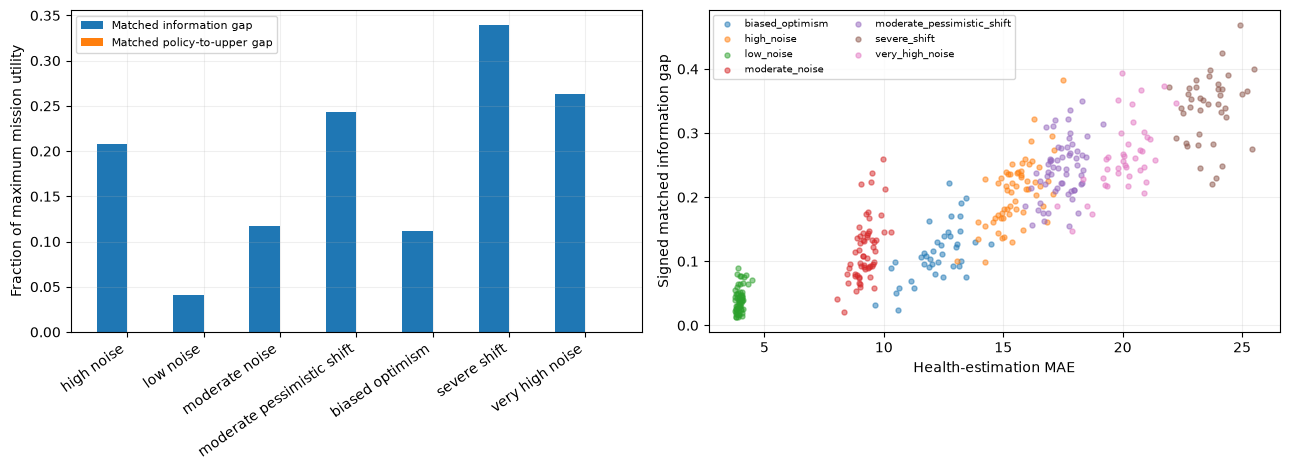

Results ZIP: Decision_Reliability_Matched_Oracle_Results.zip


In [8]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
g=summary[summary.policy=='full'].copy()
xs=np.arange(len(g)); labels=g.scenario.str.replace('_',' ',regex=False)
axes[0].bar(xs-.2,g.information_gap_safe_utility_ratio_mean,width=.4,label='Matched information gap')
axes[0].bar(xs+.2,g.matched_policy_gap_mean,width=.4,label='Matched policy-to-upper gap')
axes[0].set_xticks(xs,labels,rotation=35,ha='right');axes[0].set_ylabel('Fraction of maximum mission utility');axes[0].legend(fontsize=8)
for name,gg in selected.groupby('scenario'):
    axes[1].scatter(gg.estimation_mae,gg.information_gap_safe_utility_ratio,s=13,alpha=.5,label=name)
axes[1].set(xlabel='Health-estimation MAE',ylabel='Signed matched information gap');axes[1].legend(fontsize=7,ncol=2)
for ax in axes:ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(os.path.join(OUT,'matched_oracle_diagnostics.png'),dpi=160)
plt.show()
meta={'experiment':'Experiment 13: matched-oracle audit','source':'Experiment 12 model, same seeds and parameters',
      'fixed_policies':POLICIES,'worlds_main_per_scenario':REPS_MAIN,'worlds_robust_per_scenario':REPS_ROBUST,
      'matched_oracle':'same allocator and policy parameters; cap as observed score and sigma=0',
      'upper_bound':'per-timestep maximum safe task utility without switching cost',
      'cautions':['synthetic scalar capability','signed information gap is not guaranteed positive',
                  'matched oracle is not an optimizer for safe utility',
                  'within-scenario associations are descriptive, not causal',
                  'no external flight validation']}
with open(os.path.join(OUT,'matched_oracle_methodology.json'),'w') as f:json.dump(meta,f,indent=2)
archive='Decision_Reliability_Matched_Oracle_Results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for file in sorted(os.listdir(OUT)):z.write(os.path.join(OUT,file),arcname=file)
print('Results ZIP:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:pass